# Лабораторная работа \#8: Предобработка данных

## Задание

1. Загрузить датасет Palmer Penguins
2. Разделить на численные и категориальные признаки
3. Провести базовый визуальный анализ, попытаться определить наиболее важные признаки. Попробовать pairplot для numeric-ов
4. Заместить пропуски в численных медианой, в категориальных - самым частым значением (использовать SimpleImputer)
5. Попробовать на категориальных LabelEncoder и OneHotEncoder. Закодировать target столбец LabelEncoder-ом, остальное OneHot
6. Объединить всё в новый датафрейм. Разделить датафрейм на X и y
7. Подготовить выборки с помощью train_test_split
8. Обучить DecisionTree и RandomForest. Посмотреть результаты с помощью classification_report.
9. Посмотреть свойство feature_importances_ у RandomForest

## Выполнение работы

### Импорты данных

In [51]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from random import *

# NOTICE: sklearn ОЧЕНЬ важная библиотека для машинного обучения
# Знакомьтесь, вы её часто будете видеть
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, confusion_matrix

# Отключение предупреждений. Если код работает, кому они нужны, правда?)
import warnings
warnings.filterwarnings('ignore')

### Загрузка датасета, визуальный анализ

In [26]:
penguins = sns.load_dataset('penguins')
penguins = penguins.sample(frac=1)

In [27]:
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
71,Adelie,Torgersen,39.7,18.4,190.0,3900.0,Male
311,Gentoo,Biscoe,52.2,17.1,228.0,5400.0,Male
60,Adelie,Biscoe,35.7,16.9,185.0,3150.0,Female
35,Adelie,Dream,39.2,21.1,196.0,4150.0,Male
229,Gentoo,Biscoe,46.8,15.4,215.0,5150.0,Male


In [28]:
penguins.info()

<class 'pandas.core.frame.DataFrame'>
Index: 344 entries, 71 to 101
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 21.5+ KB


В данном случае визуально можно определить, какие столбцы (признаки) содержат численные значения, а какие нет. Для дальнейшей работы данные признаки следует разделить. В нашем случае разделим на списки `num_features` для численных (numeric) и `cat_features` для категориальных (categoriсal). В списках будут содержатся названия столбцов. Тогда для обращения к соответствующим данным можно использовать `df[num_features]` или `df[cat_features]`

Кроме того, хорошей практикой является отдельное выделение целевого признака. Мы это сделаем, создав переменную `label`, равную `species`

In [29]:
num_features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
cat_features = ['species', 'island', 'sex']
label = "species"

In [30]:
df = penguins
for i in num_features + cat_features:
  print('NaNs in', i, '=', df[i].isna().sum())

NaNs in bill_length_mm = 2
NaNs in bill_depth_mm = 2
NaNs in flipper_length_mm = 2
NaNs in body_mass_g = 2
NaNs in species = 0
NaNs in island = 0
NaNs in sex = 11


Для анализа данных полезно определять взаимозависимости между признаками, особенно численными. Попарные зависимости удобно анализировать с помощью pairplot. Цветом указаны разные классы целевого признака, по осям - область значений численных признаков

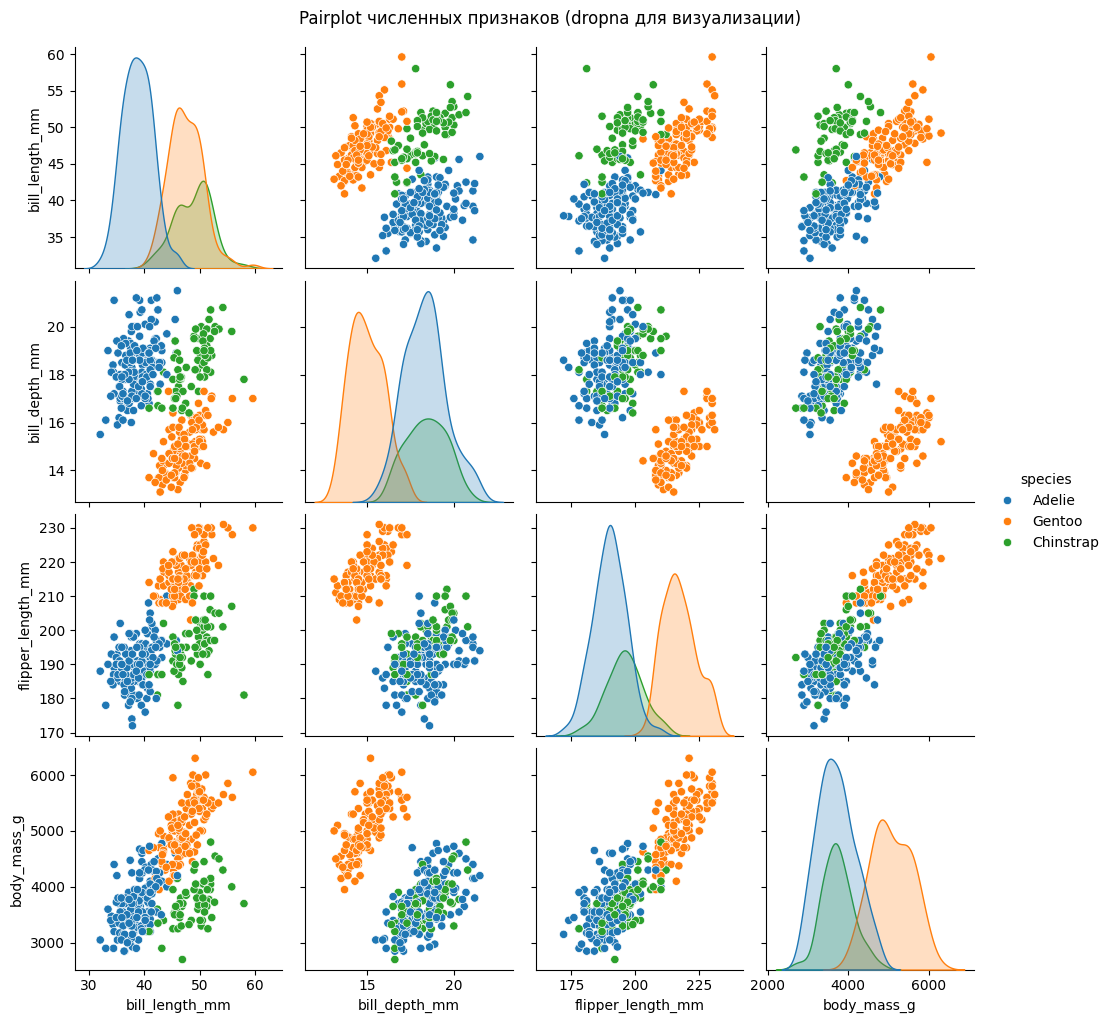

In [31]:
sns.pairplot(penguins[num_features + [label]].dropna(), hue=label, corner=False)
plt.suptitle('Pairplot численных признаков (dropna для визуализации)', y=1.02)
plt.show()

Визуального анализа взаимосвязей признаков бывает недостаточно. Для более подробных результатов часто используется так называемая **матрица корреляции**. Грубо говоря, это показатель того, насколько сильно и в каком направлении связаны между собой числовые признаки.

Корреляция показывает, как изменяются два признака вместе:

- Положительная — признаки растут вместе;
- Отрицательная — один растёт, другой уменьшается;
- Около 0 — связи почти нет.

В pandas построить корреляцию очень просто с помощью функции `corr` для датафрейма (набора numeric признаков). Визуализировать её можно с помощью heatmap из библиотеки seaborn (`sns.heatmap()`).

<Axes: >

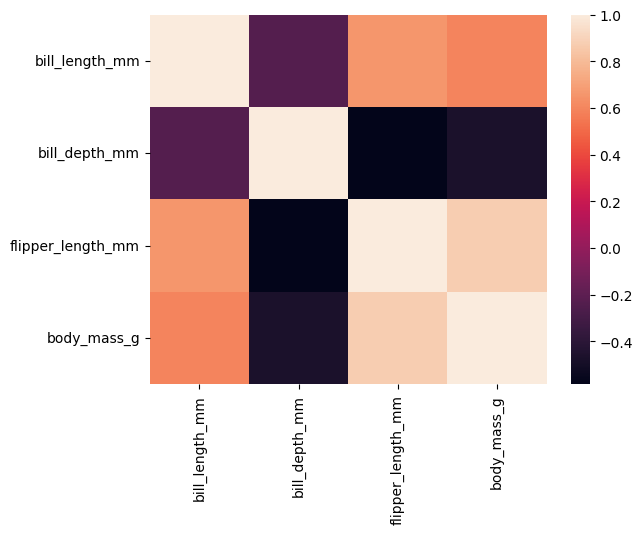

In [32]:
# TODO: построить и визуализировать матрицу корреляции
sns.heatmap(df[num_features].corr())

### Заполнение пропусков

Принято делить данные на два набора: признаки и целевые даннные, `X` и `y` соответственно

In [33]:
X = df.drop([label], axis=1)
y = penguins[label]
display(X)

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
71,Torgersen,39.7,18.4,190.0,3900.0,Male
311,Biscoe,52.2,17.1,228.0,5400.0,Male
60,Biscoe,35.7,16.9,185.0,3150.0,Female
35,Dream,39.2,21.1,196.0,4150.0,Male
229,Biscoe,46.8,15.4,215.0,5150.0,Male
...,...,...,...,...,...,...
214,Dream,45.7,17.0,195.0,3650.0,Female
44,Dream,37.0,16.9,185.0,3000.0,Female
245,Biscoe,46.1,15.1,215.0,5100.0,Male
16,Torgersen,38.7,19.0,195.0,3450.0,Female


Ранее мы уже заполняли NaN значения в датафрейме какими-то простыми значениями вроде медианы. Это можно делать в автоматизированном режиме, используя `SimpleImputer` – инструмент из `scikit-learn`.

In [36]:
num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")
cat_features.remove(label)

X[num_features] = num_imputer.fit_transform(X[num_features])
X[cat_features] = cat_imputer.fit_transform(X[cat_features])

### Кодирование категориальных признаков

## Что делает LabelEncoder и зачем

Модели машинного обучения ждут числа, а не строки.

Если целевая переменная (y) — это строки (например: "Adelie", John", "Jim"), то их нужно превратить в числа (0, 1, 2).

LabelEncoder как раз нумерует классы: сортирует уникальные значения и даёт им индексы.

Пример: classes_ = ['Adelie', 'John', 'Jim'] → Adelie→0, John→1, Jim→2.

In [37]:
le = LabelEncoder()
y = le.fit_transform(y)
print('Target classes:', le.classes_)
y

Target classes: ['Adelie' 'Chinstrap' 'Gentoo']


array([0, 2, 0, 0, 2, 1, 0, 2, 2, 0, 0, 2, 0, 2, 1, 2, 2, 2, 1, 0, 2, 0,
       0, 2, 0, 0, 1, 0, 0, 0, 2, 0, 0, 0, 2, 2, 0, 1, 1, 2, 0, 0, 2, 2,
       0, 0, 0, 2, 0, 0, 2, 1, 0, 0, 1, 0, 2, 0, 0, 2, 2, 1, 0, 0, 1, 0,
       2, 2, 0, 2, 0, 2, 2, 2, 0, 2, 2, 2, 0, 2, 0, 0, 2, 2, 0, 0, 0, 0,
       1, 0, 0, 0, 2, 2, 2, 1, 0, 0, 0, 1, 0, 2, 0, 0, 0, 0, 2, 2, 0, 0,
       0, 0, 2, 1, 0, 1, 0, 1, 1, 2, 0, 1, 0, 0, 2, 2, 1, 2, 1, 0, 0, 2,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 2, 0, 1, 1, 2, 0, 2, 2, 2, 1, 0, 2, 2,
       2, 2, 0, 0, 2, 2, 0, 2, 1, 0, 0, 2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 1,
       1, 1, 0, 1, 2, 2, 0, 2, 2, 1, 0, 2, 1, 2, 2, 0, 2, 0, 2, 0, 2, 2,
       2, 1, 1, 1, 0, 2, 1, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 2, 1, 2, 2, 0,
       0, 2, 0, 2, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 2, 2, 1, 2, 1, 0, 0,
       0, 0, 0, 0, 1, 2, 0, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 1, 2, 0, 0, 2,
       0, 0, 0, 0, 0, 1, 2, 1, 0, 2, 1, 2, 2, 1, 0, 2, 2, 1, 0, 2, 1, 2,
       2, 2, 0, 0, 1, 2, 2, 0, 1, 0, 0, 1, 0, 2, 0,

Компьютерные модели понимают только числа. Если в таблице есть текст (типа "male", "female", "Biscoe"…), его надо превратить в цифры.
One-Hot Encoding делает из одной текстовой колонки несколько колонок с нулями и единицами.

Пример

Было (одна колонка island):

island
Biscoe
Dream
Biscoe


Станет (три колонки, по одной на каждое значение):

island_Biscoe  101
island_Dream  010
island_Torgersen 000


In [38]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_encoded = pd.DataFrame(encoder.fit_transform(X[cat_features]),
                         columns=encoder.get_feature_names_out(cat_features),
                         index=X.index)

что происходит далее:

X[num_features]
– берём из исходной таблицы только числовые признаки (например, bill_length_mm, flipper_length_mm и т.п.).
num_features — это список названий этих колонок.

X_encoded
– это закодированные категориальные признаки после One-Hot (много колонок из 0/1: island_Biscoe, sex_FEMALE, …).

pd.concat([ ... ], axis=1)
– склеиваем по столбцам (axis=1 значит «рядом»).
В результате получаем одну общую таблицу с числовыми + one-hot колонками.

X = ...
– сохраняем склеенную таблицу обратно в переменную X (теперь это уже «готовые к модели» признаки).



In [39]:
X = pd.concat([X[num_features],
                     X_encoded], axis=1)

X.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Biscoe,island_Dream,island_Torgersen,sex_Female,sex_Male
71,39.7,18.4,190.0,3900.0,0.0,0.0,1.0,0.0,1.0
311,52.2,17.1,228.0,5400.0,1.0,0.0,0.0,0.0,1.0
60,35.7,16.9,185.0,3150.0,1.0,0.0,0.0,1.0,0.0
35,39.2,21.1,196.0,4150.0,0.0,1.0,0.0,0.0,1.0
229,46.8,15.4,215.0,5150.0,1.0,0.0,0.0,0.0,1.0


### Подготовка тренировочной и тестовой выборки

Что делает код далее

train_test_split — случайно делит данные на обучение (train) и тест (test).

test_size=0.2 — тестовая выборка = 20% строк, обучающая = 80%.

random_state=42 — "ядро" генератора случайных чисел. С этим параметром деление будет одинаковым при каждом запуске.

stratify=y — важно для классификации: сохраняет доли классов (например, 70%/30%) и в train, и в test. Без этого на небольших датасетах тест мог бы случайно получить перекос по классам.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(275, 9) (69, 9)


### Запуск классификатора, анализ результатов

RandomForestClassifier — это «лес» из нескольких деревьев решений. Каждое дерево голосует, и лес выбирает самый частый класс.

n_estimators=3 — всего 3 дерева

random_state=42 — чтобы результаты воспроизводились.

n_jobs=-1 — использовать все доступные ядра (ускоряет обучение).

In [48]:
model = RandomForestClassifier(n_estimators=3, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

y_pred= model.predict(X_test)

print("Точность классификатора:", accuracy_score(y_test, y_pred))

Точность классификатора: 0.9420289855072463


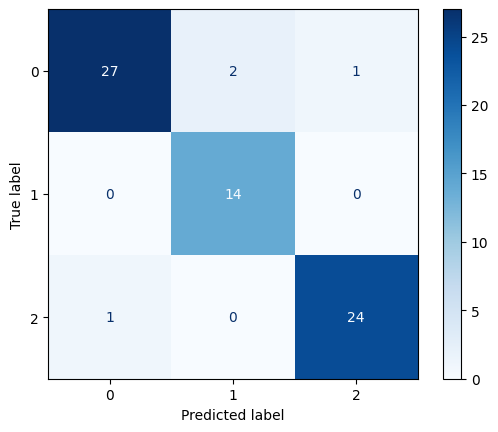

In [46]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=model.classes_).plot(cmap="Blues")
plt.show()

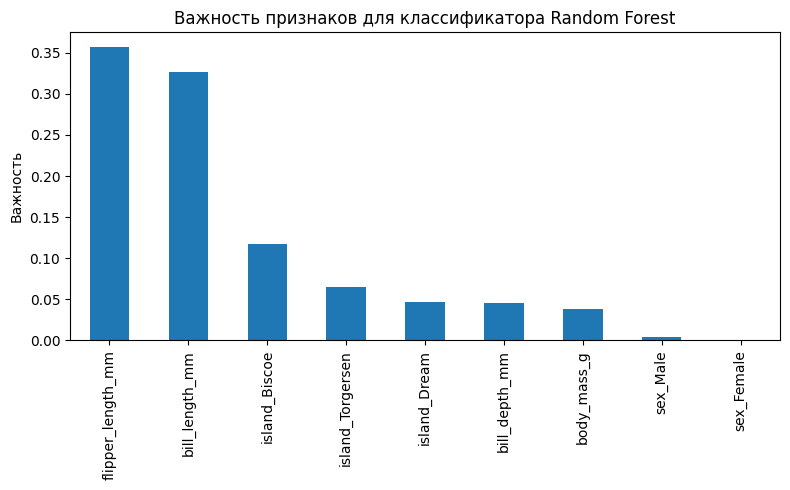

In [49]:
importances = model.feature_importances_
feat_names = X.columns
feat_imp = pd.Series(importances, index=feat_names).sort_values(ascending=False)

plt.figure(figsize=(8,5))
feat_imp.head(15).plot.bar()
plt.title('Важность признаков для классификатора Random Forest')
plt.ylabel('Важность')
plt.tight_layout()
plt.show()

В train_test_split: test_size = 0.07636846590886803 , random_state = 58
В RandomForestClassifier: n_estimators = 7 , random_state = 2564889603
Трейн к тесту: (317, 9) (27, 9)
Точность классификатора: 1.0


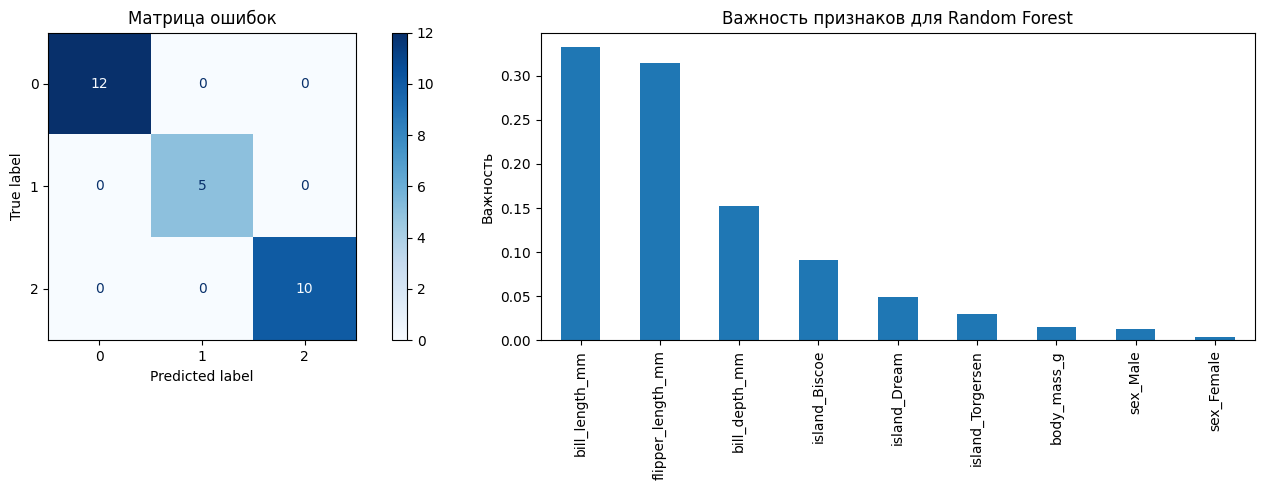





В train_test_split: test_size = 0.8416114469981281 , random_state = 82
В RandomForestClassifier: n_estimators = 20 , random_state = 700771252
Трейн к тесту: (54, 9) (290, 9)
Точность классификатора: 0.9862068965517241


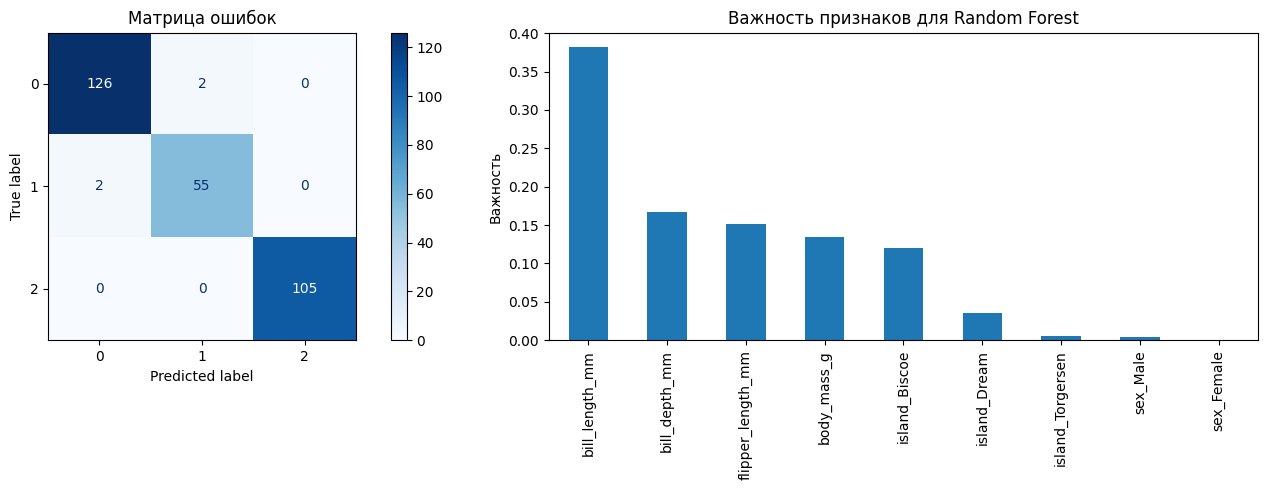





В train_test_split: test_size = 0.33084755335271954 , random_state = 69
В RandomForestClassifier: n_estimators = 4 , random_state = 1584516040
Трейн к тесту: (230, 9) (114, 9)
Точность классификатора: 0.9736842105263158


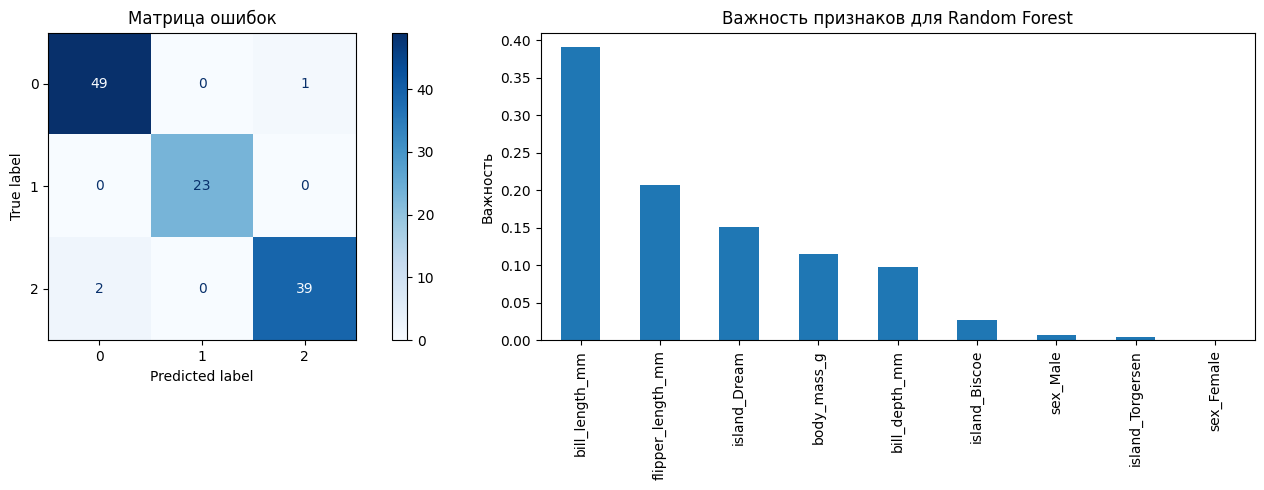





В train_test_split: test_size = 0.4830629747756472 , random_state = 90
В RandomForestClassifier: n_estimators = 19 , random_state = 2773378109
Трейн к тесту: (177, 9) (167, 9)
Точность классификатора: 0.9820359281437125


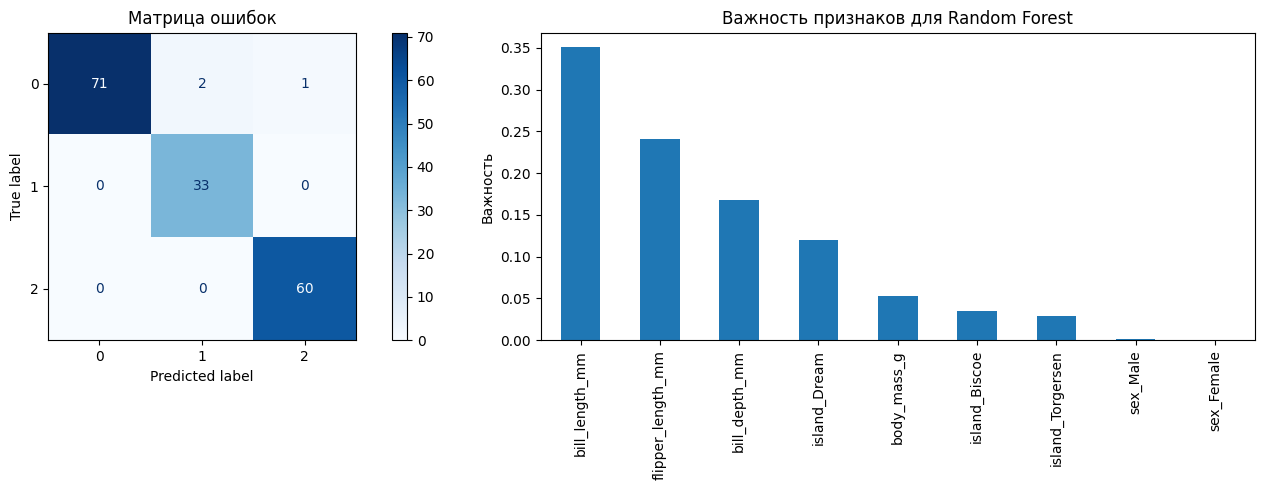





В train_test_split: test_size = 0.8966868429487792 , random_state = 69
В RandomForestClassifier: n_estimators = 19 , random_state = 31953639
Трейн к тесту: (35, 9) (309, 9)
Точность классификатора: 0.9644012944983819


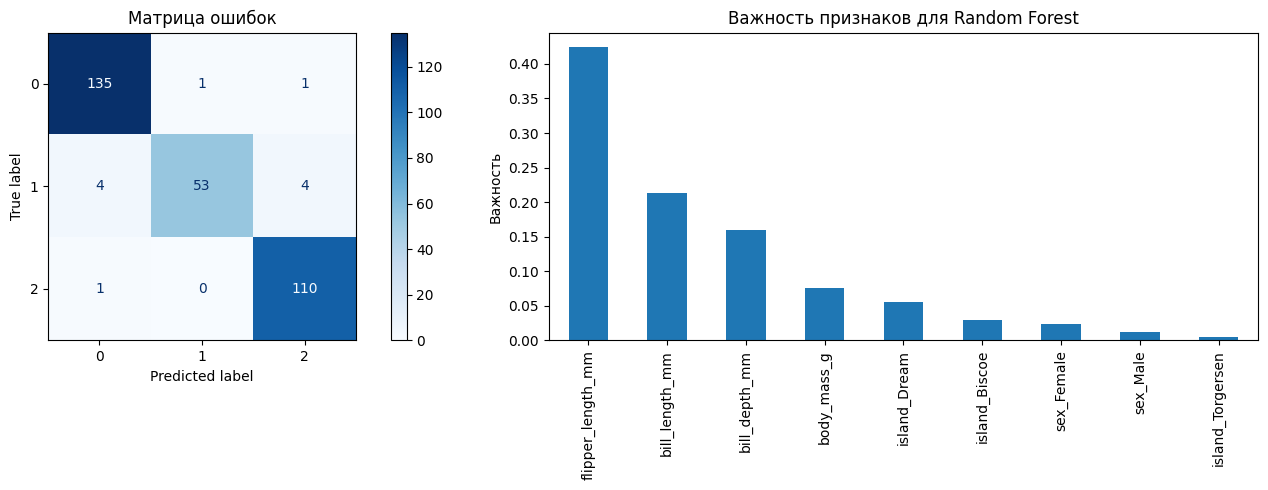

In [67]:

for i in range(1, 6):
  tsts = random()
  rnst1 = randint(30, 100)

  nestim = randint(3, 20)
  rnst2 = randint(0, 4294967295)

  print('В train_test_split:', 'test_size =', tsts, ', random_state =', rnst1)
  print('В RandomForestClassifier:', 'n_estimators =', nestim, ', random_state =', rnst2)

  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=tsts, random_state=rnst1, stratify=y)
  print('Трейн к тесту:', X_train.shape, X_test.shape)


  model = RandomForestClassifier(n_estimators=nestim, random_state=rnst2, n_jobs=-1)
  model.fit(X_train, y_train)
  y_pred= model.predict(X_test)
  print("Точность классификатора:", accuracy_score(y_test, y_pred))


  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

  ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                        display_labels=model.classes_).plot(cmap="Blues", ax=ax1)
  ax1.set_title('Матрица ошибок')

  importances = model.feature_importances_
  feat_names = X.columns
  feat_imp = pd.Series(importances, index=feat_names).sort_values(ascending=False)
  feat_imp.head(15).plot.bar(ax=ax2)
  ax2.set_title('Важность признаков для Random Forest')
  ax2.set_ylabel('Важность')

  plt.tight_layout()
  plt.show()

  print('\n' * 3)

print('Вывод: больше деревьев (n_estimators) и меньше трейн тест (test_size) -- больше точность')